# Results

Reads the [results store](../autobus-docs/docs/concepts/experiment.md) and
nothing else. **No simulation runs here**, and no CARLA server is needed — so
this works whether or not an experiment is in progress, and shows everything
recorded so far.

Re-run it any time. If a campaign is running in another process, re-running
this simply picks up the trials that have finished since.

Each chart sits beside the table it summarises. That is partly for reading and
partly a requirement: one palette slot falls below 3:1 contrast on a light
surface, and a visible table is the accepted relief.

## House style

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from cycler import cycler

# Categorical slots 1-3 of the project's validated palette. Checked rather
# than chosen by eye: all-pairs CVD separation 9.2 (>=8), normal-vision 24.0
# (>=15), both on the light surface below. Three is the cap that clears
# all-pairs; a fourth series folds into "Other" or gets its own facet.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
PRIMARY = SERIES[0]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT,
    "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "figure.dpi": 110,
})
pd.set_option("display.max_rows", 200)
print("style applied")

style applied


In [2]:
import math
import statistics

from scipy import stats

from src.experiment.store import DEFAULT_RUNS_DIR, load_frame, load_runs
from src.experiment.summary import summarize_results
from src.experiment.store import to_results

from IPython.display import Markdown, display

RUNS = DEFAULT_RUNS_DIR
frame = load_frame(RUNS)
records = load_runs(RUNS)

if frame.empty:
    print("The store is empty. Run notebooks/synthetic-campaign.ipynb first.")
else:
    print(f"{len(frame)} runs recorded")

2312 runs recorded


## What is in the store

A run is one `(parameters, seed)` pair. Runs from different maps, backends,
loads or policy settings are different runs and never merge, so everything
recorded — synthetic and CARLA alike — coexists here.

In [3]:
KEY = [
    "identity.world.backend",
    "identity.world.town" if "identity.world.town" in frame.columns
    else "identity.world.map",
    "identity.trial.max_requests",
    "identity.trial.demand_interval_s",
    "identity.trial.max_wait_s",
]
KEY = [c for c in KEY if c in frame.columns]


def scenarios(f):
    """
    Group runs by the setting they share, ignoring policy and seed.
    :param f: The store as a frame.
    :return: One row per scenario, with its run and seed counts.
    """
    grouped = f.groupby(KEY, dropna=False).agg(
        runs=("run_id", "count"),
        policies=("identity.policy", "nunique"),
        seeds=("identity.seed", "nunique"),
    )
    return grouped.sort_values("runs", ascending=False)


if not frame.empty:
    display(scenarios(frame))

runs  \
identity.world.backend identity.world.town identity.trial.max_requests identity.trial.demand_interval_s identity.trial.max_wait_s         
MockBackend            NaN                 200                         60.0                             NaN                        1140   
                                                                                                        900.0                      1140   
CarlaBackend           Town01              12                          150.0                            2400.0                       24   
                                           4                           120.0                            1800.0                        4   
                                           6                           120.0                            2400.0                        4   

                                                                                                                                   policies  \
identity.world.backend identity.world.town identity.trial.max_requests identity.trial.demand_interval_s identity.trial.max_wait_s             
MockBackend            NaN                 200                         60.0                             NaN                              19   
                                                                                                        900.0                            19   
CarlaBackend           Town01              12                          150.0                            2400.0                            3   
                                           4                           120.0                            1800.0                            2   
                                           6                           120.0                            2400.0                            1   

                                                                                                                                   seeds  
identity.world.backend identity.world.town identity.trial.max_requests identity.trial.demand_interval_s identity.trial.max_wait_s         
MockBackend            NaN                 200                         60.0                             NaN                           60  
                                                                                                        900.0                         60  
CarlaBackend           Town01              12                          150.0                            2400.0                         8  
                                           4                           120.0                            1800.0                         2  
                                           6                           120.0                            2400.0                         2

## Pick a scenario

Defaults to the one with the most runs. Change `SCENARIO` to any row index
from the table above to look at a different one.

In [4]:
SCENARIO = None   # None = the scenario with the most runs

if not frame.empty:
    table = scenarios(frame)
    chosen = table.index[0] if SCENARIO is None else SCENARIO
    if not isinstance(chosen, tuple):
        chosen = (chosen,)
    mask = pd.Series(True, index=frame.index)
    for column, value in zip(KEY, chosen):
        mask &= (frame[column].isna() if pd.isna(value)
                 else frame[column] == value)
    subset = frame[mask]
    wanted = set(subset["run_id"])
    scenario_records = [r for r in records if r.run_id in wanted]
    print(dict(zip(KEY, chosen)))
    print(f"{len(scenario_records)} runs, "
          f"{subset['identity.policy'].nunique()} policies, "
          f"{subset['identity.seed'].nunique()} seeds")

{'identity.world.backend': 'MockBackend', 'identity.world.town': nan, 'identity.trial.max_requests': np.int64(200), 'identity.trial.demand_interval_s': np.float64(60.0), 'identity.trial.max_wait_s': np.float64(nan)}
1140 runs, 19 policies, 60 seeds


## How the policies compare

In [5]:
if not frame.empty:
    results = to_results(scenario_records, paired=True)
    display(Markdown(summarize_results(results).markdown))

| Property | Constrained | Deviated | Fixed route | Marginal cost | Nearest unserved | Reordering W1200 | Reordering W1800 | Reordering W450 | Reordering W600 | Reordering W750 | Reordering W900 | Ride bounded | Skip-stop | Window W1200 | Window W1800 | Window W450 | Window W600 | Window W750 | Window W900 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) |
| Cancelled requests | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) |
| Mean wait time | 407.6 s (±2.7%) | 866.2 s (±8.5%) | 365.3 s (±1.2%) | 671.1 s (±7.3%) | 671.1 s (±7.3%) | 325.1 s (±1.2%) | 325.1 s (±1.2%) | 376.1 s (±3.3%) | 338.5 s (±1.2%) | 325.6 s (±1.3%) | 323.7 s (±1.3%) | 486.5 s (±3.6%) | 370.1 s (±1.1%) | 333.5 s (±1.2%) | 333.5 s (±1.2%) | 380.6 s (±3.4%) | 341.0 s (±1.2%) | 330.0 s (±1.3%) | 332.3 s (±1.1%) |
| P90 wait time | 822.4 s (±4.2%) | 2788.0 s (±11.8%) | 659.8 s (±0.6%) | 2028.0 s (±11.3%) | 2028.0 s (±11.3%) | 652.3 s (±0.9%) | 651.9 s (±0.9%) | 782.3 s (±5.4%) | 632.2 s (±1.2%) | 649.8 s (±1.0%) | 648.4 s (±1.0%) | 1112.5 s (±6.1%) | 664.8 s (±0.7%) | 662.3 s (±0.9%) | 662.3 s (±0.9%) | 780.5 s (±5.1%) | 631.8 s (±1.3%) | 654.5 s (±0.8%) | 662.0 s (±0.7%) |
| Mean ride time | 327.3 s (±3.1%) | 839.4 s (±7.8%) | 371.1 s (±1.1%) | 598.0 s (±6.7%) | 598.0 s (±6.7%) | 280.5 s (±1.4%) | 280.5 s (±1.4%) | 380.7 s (±3.2%) | 321.5 s (±1.8%) | 287.0 s (±1.4%) | 281.5 s (±1.3%) | 412.4 s (±4.3%) | 369.9 s (±1.1%) | 280.6 s (±1.4%) | 280.6 s (±1.4%) | 395.6 s (±3.6%) | 329.2 s (±2.2%) | 287.7 s (±1.4%) | 282.1 s (±1.5%) |
| Fulfillment rate | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) |
| Served fraction | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) |
| Throughput | 0.9 req/min (±0.4%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.3%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.3%) | 0.9 req/min (±0.3%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.3%) | 0.9 req/min (±0.3%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.3%) | 0.9 req/min (±0.3%) | 0.9 req/min (±0.3%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.4%) | 0.9 req/min (±0.3%) |
| Tick snapshots | 12842.9 (±0.4%) | 13030.5 (±0.4%) | 12935.7 (±0.3%) | 12864.5 (±0.4%) | 12863.8 (±0.4%) | 12716.3 (±0.3%) | 12724.0 (±0.3%) | 12755.7 (±0.4%) | 12744.9 (±0.4%) | 12709.1 (±0.3%) | 12709.6 (±0.3%) | 12894.9 (±0.4%) | 12853.9 (±0.3%) | 12733.3 (±0.3%) | 12733.3 (±0.3%) | 12761.1 (±0.5%) | 12778.9 (±0.4%) | 12723.0 (±0.4%) | 12716.8 (±0.3%) |
| Fulfilled (wait samples) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) | 200.0 (±0.0%) |
| Min wait time | 2.0 s (±37.4%) | 2.3 s (±36.8%) | 1.6 s (±51.4%) | 2.1 s (±34.5%) | 2.1 s (±34.5%) | 1.9 s (±43.7%) | 1.9 s (±43.7%) | 1.5 s (±48.8%) | 1.8 s (±38.6%) | 1.8 s (±37.7%) | 1.8 s (±43.1%) | 1.8 s (±35.5%) | 2.4 s (±42.6%) | 2.3 s (±31.6%) | 2.3 s (±31.6%) | 1.2 s (±53.2%) | 1.7 s (±50.9%) | 1.8 s (±43.3%) | 2.2 s (±30.6%) |
| Max wait time | 1880.0 s (±6.5%) | 5413.5 s (±9.2%) | 736.0 s (±0.2%) | 4436.9 s (±8.9%) | 4436.9 s (±8.9%) | 855.5 s (±3.4%) | 875.5 s (±4.3%) | 2068.5 s (±7.0%) | 1381.7 s (±6.9%) | 781.5 s (±2.5%) | 808.3 s (±1.7%) | 2474.8 s (±6.9%) | 846.7 s (±3.3%) | 921.6 s (±3.0%) | 921.6 s (±3.0%) | 2123.6 s (±7.9%) | 1412.5 s (±6.4%) | 802.6 s (±3.0%) | 857.5 s (±1.6%) |
| Min ride time | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) | 15.8 s (±0.0%) |
| Max ride time | 1758.9 s (±7.7%) | 5320.1 s (±9.0%) | 723.9 s (±0.0%) | 4400.4 s (±8.7%) | 4400.4 s (±8.7%) | 752.8 s (±3.7%) | 751.3 s (±3.6%) | 1998.3 s (±7.0%) | 1299.8 s (±7.6%) | 750.1 s (±3.6%) | 732.0 s (±3.4%) | 2450.1 s (±7.2%) | 723.9 s (±0.0%) | 818.7 s (±2.6%) | 818.7 s (±2.6%) | 2103.8 s (±8.0%) | 1359.0 s (±7.0%) | 801.4 s (±5.1%) | 800.5 s (±2.5%) |

The bars below show the same numbers with 95% confidence intervals. One
series per panel, so the category axis carries identity and no legend is
needed; a shorter bar is better for wait and ride, longer for the other two.

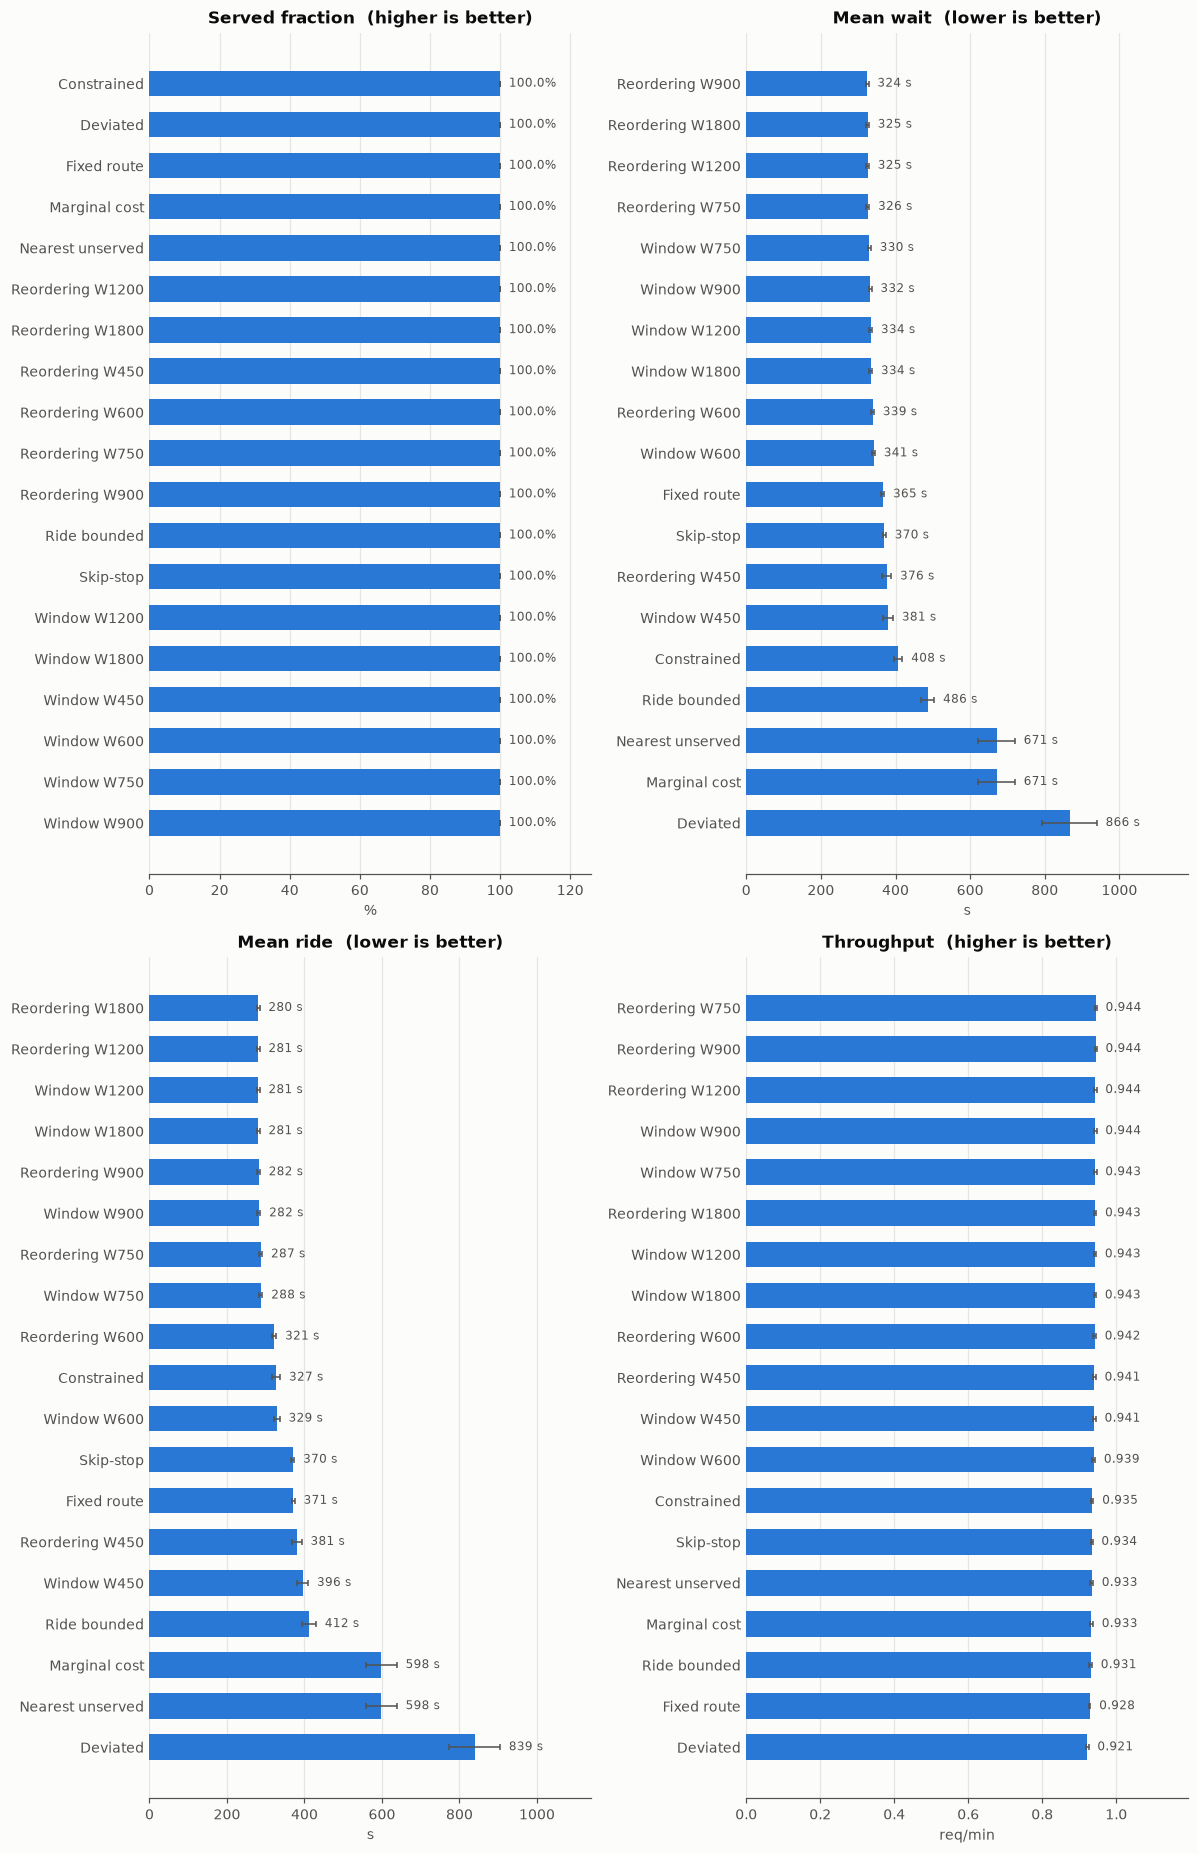

In [6]:
KPIS = [
    ("served_fraction", "Served fraction", 100.0, "%", "higher"),
    ("mean_wait_time", "Mean wait", 1.0, "s", "lower"),
    ("mean_ride_time", "Mean ride", 1.0, "s", "lower"),
    ("throughput", "Throughput", 1.0, "req/min", "higher"),
]


def kpi_stats(results, field, scale):
    """
    Mean and 95% CI half-width per policy for one KPI.
    :param results: Policy label to trial results.
    :param field: KPISnapshot attribute name.
    :param scale: Multiplier applied before reporting.
    :return: Mapping of label to (mean, half-width).
    """
    out = {}
    for label, runs in results.items():
        values = [getattr(r.kpi, field) for r in runs
                  if getattr(r.kpi, field) is not None]
        if not values:
            continue
        mean = statistics.fmean(values) * scale
        if len(values) > 1:
            sd = statistics.stdev(values) * scale
            half = stats.t.ppf(0.975, len(values) - 1) * sd / len(values) ** .5
        else:
            half = 0.0
        out[label] = (mean, half)
    return out


def kpi_panel(results, kpis=KPIS):
    """
    Draw one horizontal bar panel per KPI, sorted best-first.
    :param results: Policy label to trial results.
    :param kpis: (field, title, scale, unit, direction) tuples.
    :return: The figure.
    """
    figure, axes = plt.subplots(2, 2, figsize=(11, 1.0 + 0.42 * len(results)
                                               * 2))
    for axis, (field, title, scale, unit, direction) in zip(
            axes.ravel(), kpis):
        data = kpi_stats(results, field, scale)
        fmt = (lambda v: f"{v:.3f}") if unit == "req/min" else (
            (lambda v: f"{v:.1f}%") if unit == "%" else
            (lambda v: f"{v:,.0f} s"))
        order = sorted(data, key=lambda k: data[k][0],
                       reverse=(direction == "higher"))
        values = [data[k][0] for k in order]
        errors = [data[k][1] for k in order]
        positions = range(len(order))
        axis.barh(positions, values, xerr=errors, color=PRIMARY, height=0.62,
                  error_kw=dict(ecolor=INK_SOFT, lw=1.0, capsize=2))
        axis.set_yticks(list(positions), order)
        axis.invert_yaxis()
        axis.set_title(f"{title}  ({'higher' if direction == 'higher' else 'lower'} is better)")
        axis.set_xlabel(unit)
        axis.grid(axis="x")
        axis.set_axisbelow(True)
        axis.spines["left"].set_visible(False)
        axis.tick_params(axis="y", length=0)
        # Labels sit beyond the whisker, not on top of it: the error bar is
        # the reason a reader trusts the bar, so it must stay legible.
        reach = max((v + e for v, e in zip(values, errors)), default=1.0)
        for position, value, error in zip(positions, values, errors):
            axis.text(value + error + reach * 0.025, position,
                      fmt(value), va="center", fontsize=8, color=INK_SOFT)
        axis.set_xlim(0, reach * 1.26)
    figure.tight_layout()
    return figure


if not frame.empty:
    kpi_panel(results)
    plt.show()

## Against the design review's criteria

Two things are asked for: fulfilment at or above 80%, and a **positive sum of
percentage differences** across the other three KPIs when compared with a
fixed-route bus. Both are computed here against whichever fixed-route policy
is present in the scenario.

In [7]:
def criteria(results, baseline_hint="Fixed route"):
    """
    Score every policy against the fixed-route baseline.
    :param results: Policy label to trial results.
    :param baseline_hint: Label of the comparator.
    :return: Markdown table, or a note if no baseline is present.
    """
    if baseline_hint not in results:
        return f"*No `{baseline_hint}` runs in this scenario to compare with.*"

    def mean_of(runs, field):
        """Average one KPI over a policy's runs."""
        values = [getattr(r.kpi, field) for r in runs
                  if getattr(r.kpi, field) is not None]
        return statistics.fmean(values) if values else float("nan")

    base = results[baseline_hint]
    rows = ["| policy | fulfilment | wait | ride | throughput | sum | verdict |",
            "| --- | --- | --- | --- | --- | --- | --- |"]
    for label, runs in sorted(results.items()):
        if label == baseline_hint:
            continue
        fulfilment = mean_of(runs, "fulfillment_rate") * 100
        wait = (mean_of(base, "mean_wait_time")
                - mean_of(runs, "mean_wait_time")) / mean_of(
                    base, "mean_wait_time")
        ride = (mean_of(base, "mean_ride_time")
                - mean_of(runs, "mean_ride_time")) / mean_of(
                    base, "mean_ride_time")
        thru = (mean_of(runs, "throughput")
                - mean_of(base, "throughput")) / mean_of(base, "throughput")
        total = (wait + ride + thru) * 100
        passes = fulfilment >= 80 and total > 0
        rows.append(
            f"| {label} | {fulfilment:.1f}% | {wait * 100:+.1f}% | "
            f"{ride * 100:+.1f}% | {thru * 100:+.1f}% | {total:+.1f}% | "
            f"{'**PASS**' if passes else 'fail'} |")
    return "\n".join(rows)


if not frame.empty:
    display(Markdown(criteria(results)))

| policy | fulfilment | wait | ride | throughput | sum | verdict |
| --- | --- | --- | --- | --- | --- | --- |
| Constrained | 100.0% | -11.6% | +11.8% | +0.7% | +0.9% | **PASS** |
| Deviated | 100.0% | -137.1% | -126.2% | -0.7% | -264.1% | fail |
| Marginal cost | 100.0% | -83.7% | -61.2% | +0.6% | -144.3% | fail |
| Nearest unserved | 100.0% | -83.7% | -61.2% | +0.6% | -144.3% | fail |
| Reordering W1200 | 100.0% | +11.0% | +24.4% | +1.7% | +37.1% | **PASS** |
| Reordering W1800 | 100.0% | +11.0% | +24.4% | +1.7% | +37.1% | **PASS** |
| Reordering W450 | 100.0% | -3.0% | -2.6% | +1.4% | -4.1% | fail |
| Reordering W600 | 100.0% | +7.3% | +13.4% | +1.5% | +22.2% | **PASS** |
| Reordering W750 | 100.0% | +10.9% | +22.6% | +1.8% | +35.3% | **PASS** |
| Reordering W900 | 100.0% | +11.4% | +24.1% | +1.8% | +37.3% | **PASS** |
| Ride bounded | 100.0% | -33.2% | -11.1% | +0.3% | -44.0% | fail |
| Skip-stop | 100.0% | -1.3% | +0.3% | +0.6% | -0.4% | fail |
| Window W1200 | 100.0% | +8.7% | +24.4% | +1.6% | +34.7% | **PASS** |
| Window W1800 | 100.0% | +8.7% | +24.4% | +1.6% | +34.7% | **PASS** |
| Window W450 | 100.0% | -4.2% | -6.6% | +1.4% | -9.4% | fail |
| Window W600 | 100.0% | +6.6% | +11.3% | +1.2% | +19.2% | **PASS** |
| Window W750 | 100.0% | +9.7% | +22.5% | +1.7% | +33.8% | **PASS** |
| Window W900 | 100.0% | +9.0% | +24.0% | +1.7% | +34.7% | **PASS** |

## Is the sample big enough?

The bar is a confidence-interval half-width below **5% of the mean** on every
KPI. Where it is missed, the last column says how many seeds would reach it —
and extending a campaign only runs what is missing.

In [8]:
def precision(results, confidence=0.95):
    """
    Report achieved CI half-width per policy and KPI.
    :param results: Policy label to trial results.
    :param confidence: Confidence level.
    :return: Markdown table.
    """
    rows = ["| policy | KPI | mean | CI half | % of mean | seeds for 5% |",
            "| --- | --- | --- | --- | --- | --- |"]
    for label, runs in sorted(results.items()):
        for field, title, scale, unit, _ in KPIS:
            values = [getattr(r.kpi, field) for r in runs
                      if getattr(r.kpi, field) is not None]
            n = len(values)
            if n < 2:
                continue
            mean = statistics.fmean(values) * scale
            sd = statistics.stdev(values) * scale
            if mean == 0 or sd == 0:
                rows.append(f"| {label} | {title} | {mean:.4g}{unit} | 0 | "
                            f"0.0% | met |")
                continue
            half = stats.t.ppf(1 - (1 - confidence) / 2, n - 1) * sd / n ** .5
            pct = 100 * half / abs(mean)
            need = "met" if pct <= 5 else str(math.ceil(n * (pct / 5) ** 2))
            rows.append(f"| {label} | {title} | {mean:.4g}{unit} | "
                        f"{half:.3g} | {pct:.1f}% | {need} |")
    return "\n".join(rows)


if not frame.empty:
    display(Markdown(precision(results)))

| policy | KPI | mean | CI half | % of mean | seeds for 5% |
| --- | --- | --- | --- | --- | --- |
| Constrained | Served fraction | 100% | 0 | 0.0% | met |
| Constrained | Mean wait | 407.6s | 11.1 | 2.7% | met |
| Constrained | Mean ride | 327.3s | 10.1 | 3.1% | met |
| Constrained | Throughput | 0.9346req/min | 0.00381 | 0.4% | met |
| Deviated | Served fraction | 100% | 0 | 0.0% | met |
| Deviated | Mean wait | 866.2s | 73.3 | 8.5% | 172 |
| Deviated | Mean ride | 839.4s | 65.4 | 7.8% | 146 |
| Deviated | Throughput | 0.9212req/min | 0.0041 | 0.4% | met |
| Fixed route | Served fraction | 100% | 0 | 0.0% | met |
| Fixed route | Mean wait | 365.3s | 4.43 | 1.2% | met |
| Fixed route | Mean ride | 371.1s | 3.98 | 1.1% | met |
| Fixed route | Throughput | 0.9278req/min | 0.00249 | 0.3% | met |
| Marginal cost | Served fraction | 100% | 0 | 0.0% | met |
| Marginal cost | Mean wait | 671.1s | 49 | 7.3% | 128 |
| Marginal cost | Mean ride | 598s | 40.3 | 6.7% | 110 |
| Marginal cost | Throughput | 0.9331req/min | 0.00413 | 0.4% | met |
| Nearest unserved | Served fraction | 100% | 0 | 0.0% | met |
| Nearest unserved | Mean wait | 671.1s | 49 | 7.3% | 128 |
| Nearest unserved | Mean ride | 598s | 40.3 | 6.7% | 110 |
| Nearest unserved | Throughput | 0.9331req/min | 0.00412 | 0.4% | met |
| Reordering W1200 | Served fraction | 100% | 0 | 0.0% | met |
| Reordering W1200 | Mean wait | 325.1s | 3.79 | 1.2% | met |
| Reordering W1200 | Mean ride | 280.5s | 3.87 | 1.4% | met |
| Reordering W1200 | Throughput | 0.9438req/min | 0.00297 | 0.3% | met |
| Reordering W1800 | Served fraction | 100% | 0 | 0.0% | met |
| Reordering W1800 | Mean wait | 325.1s | 3.79 | 1.2% | met |
| Reordering W1800 | Mean ride | 280.5s | 3.81 | 1.4% | met |
| Reordering W1800 | Throughput | 0.9432req/min | 0.00293 | 0.3% | met |
| Reordering W450 | Served fraction | 100% | 0 | 0.0% | met |
| Reordering W450 | Mean wait | 376.1s | 12.5 | 3.3% | met |
| Reordering W450 | Mean ride | 380.7s | 12.2 | 3.2% | met |
| Reordering W450 | Throughput | 0.941req/min | 0.00385 | 0.4% | met |
| Reordering W600 | Served fraction | 100% | 0 | 0.0% | met |
| Reordering W600 | Mean wait | 338.5s | 3.96 | 1.2% | met |
| Reordering W600 | Mean ride | 321.5s | 5.87 | 1.8% | met |
| Reordering W600 | Throughput | 0.9417req/min | 0.00343 | 0.4% | met |
| Reordering W750 | Served fraction | 100% | 0 | 0.0% | met |
| Reordering W750 | Mean wait | 325.6s | 4.2 | 1.3% | met |
| Reordering W750 | Mean ride | 287s | 4.01 | 1.4% | met |
| Reordering W750 | Throughput | 0.9444req/min | 0.00316 | 0.3% | met |
| Reordering W900 | Served fraction | 100% | 0 | 0.0% | met |
| Reordering W900 | Mean wait | 323.7s | 4.08 | 1.3% | met |
| Reordering W900 | Mean ride | 281.5s | 3.56 | 1.3% | met |
| Reordering W900 | Throughput | 0.9443req/min | 0.00304 | 0.3% | met |
| Ride bounded | Served fraction | 100% | 0 | 0.0% | met |
| Ride bounded | Mean wait | 486.5s | 17.6 | 3.6% | met |
| Ride bounded | Mean ride | 412.4s | 17.6 | 4.3% | met |
| Ride bounded | Throughput | 0.9308req/min | 0.0037 | 0.4% | met |
| Skip-stop | Served fraction | 100% | 0 | 0.0% | met |
| Skip-stop | Mean wait | 370.1s | 4.21 | 1.1% | met |
| Skip-stop | Mean ride | 369.9s | 3.97 | 1.1% | met |
| Skip-stop | Throughput | 0.9337req/min | 0.00251 | 0.3% | met |
| Window W1200 | Served fraction | 100% | 0 | 0.0% | met |
| Window W1200 | Mean wait | 333.5s | 3.89 | 1.2% | met |
| Window W1200 | Mean ride | 280.6s | 3.85 | 1.4% | met |
| Window W1200 | Throughput | 0.9426req/min | 0.00311 | 0.3% | met |
| Window W1800 | Served fraction | 100% | 0 | 0.0% | met |
| Window W1800 | Mean wait | 333.5s | 3.89 | 1.2% | met |
| Window W1800 | Mean ride | 280.6s | 3.85 | 1.4% | met |
| Window W1800 | Throughput | 0.9426req/min | 0.00311 | 0.3% | met |
| Window W450 | Served fraction | 100% | 0 | 0.0% | met |
| Window W450 | Mean wait | 380.6s | 13.1 | 3.4% | met |
| Window W450 | Mean ride | 395.6s | 14.1 | 3.6% | met |
| Window W450 | Throughput | 0.9406req/min | 0.00419 | 0.4% | met |
| Window W600 | Served fraction | 100% | 0 | 0.0% | met |
| Window W600 | Mean wait | 341s | 4.05 | 1.2% | met |
| Window W600 | Mean ride | 329.2s | 7.1 | 2.2% | met |
| Window W600 | Throughput | 0.9393req/min | 0.00365 | 0.4% | met |
| Window W750 | Served fraction | 100% | 0 | 0.0% | met |
| Window W750 | Mean wait | 330s | 4.22 | 1.3% | met |
| Window W750 | Mean ride | 287.7s | 3.94 | 1.4% | met |
| Window W750 | Throughput | 0.9434req/min | 0.00335 | 0.4% | met |
| Window W900 | Served fraction | 100% | 0 | 0.0% | met |
| Window W900 | Mean wait | 332.3s | 3.71 | 1.1% | met |
| Window W900 | Mean ride | 282.1s | 4.13 | 1.5% | met |
| Window W900 | Throughput | 0.9438req/min | 0.00303 | 0.3% | met |

## Where the time actually goes

Averages hide the tail. These are every fulfilled passenger's wait, pooled
across seeds — the box spans the quartiles, the whiskers the 5th–95th
percentile, and the notch is the median.

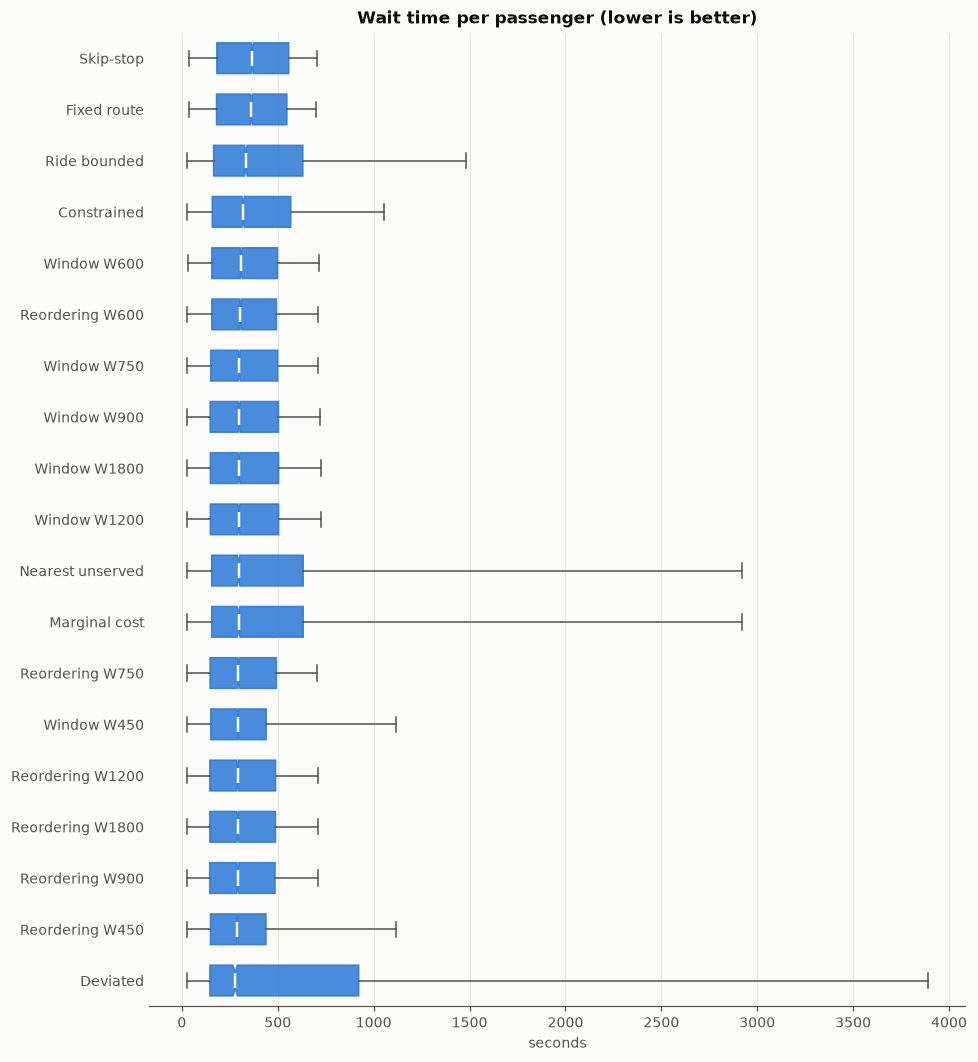

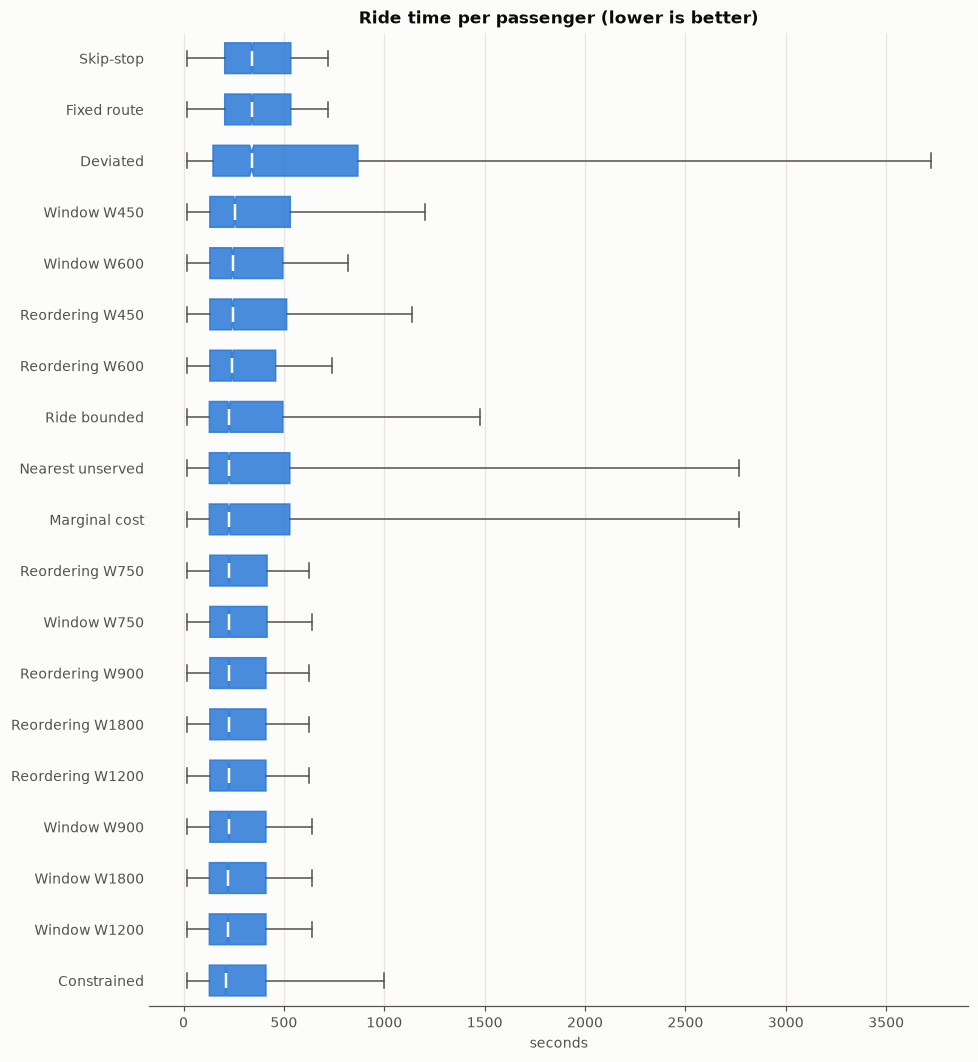

In [9]:
def wait_spread(results, field="wait_times", title="Wait time"):
    """
    Box plot of a per-passenger distribution across policies.
    :param results: Policy label to trial results.
    :param field: TrialResult attribute holding the samples.
    :param title: Chart title.
    :return: The figure, or None when there is nothing to draw.
    """
    pooled = {
        label: [v for r in runs for v in getattr(r, field)]
        for label, runs in results.items()
    }
    pooled = {k: v for k, v in pooled.items() if v}
    if not pooled:
        return None
    order = sorted(pooled, key=lambda k: statistics.median(pooled[k]))
    figure, axis = plt.subplots(figsize=(9, 0.44 * len(order) + 1.4))
    axis.boxplot([pooled[k] for k in order],
                 orientation="horizontal", notch=True,
                 whis=(5, 95), showfliers=False, widths=0.6,
                 patch_artist=True,
                 boxprops=dict(facecolor=PRIMARY, edgecolor=PRIMARY,
                               alpha=0.85),
                 medianprops=dict(color=SURFACE, lw=1.6),
                 whiskerprops=dict(color=INK_SOFT),
                 capprops=dict(color=INK_SOFT))
    axis.set_yticks(range(1, len(order) + 1), order)
    axis.set_xlabel("seconds")
    axis.set_title(f"{title} per passenger (lower is better)")
    axis.grid(axis="x")
    axis.set_axisbelow(True)
    axis.spines["left"].set_visible(False)
    axis.tick_params(axis="y", length=0)
    figure.tight_layout()
    return figure


if not frame.empty:
    wait_spread(results)
    plt.show()
    wait_spread(results, "ride_times", "Ride time")
    plt.show()

## The service window

Only present once a window sweep has run. One line per policy family, with a
95% band across seeds; the x axis is the window the policy was told to keep.

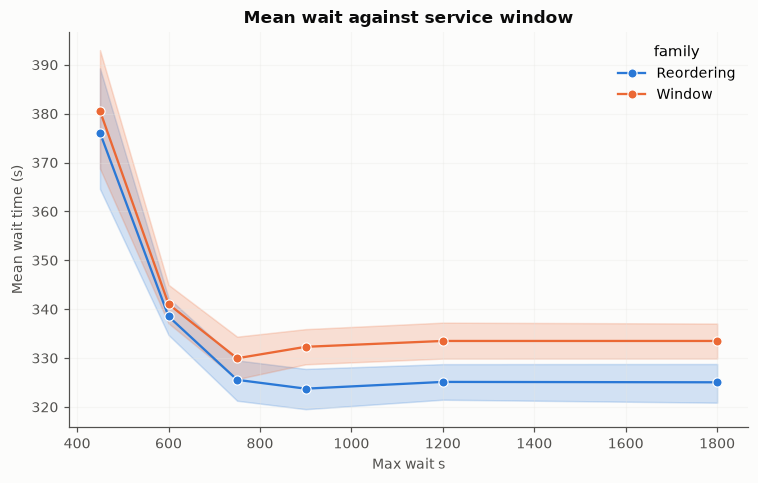

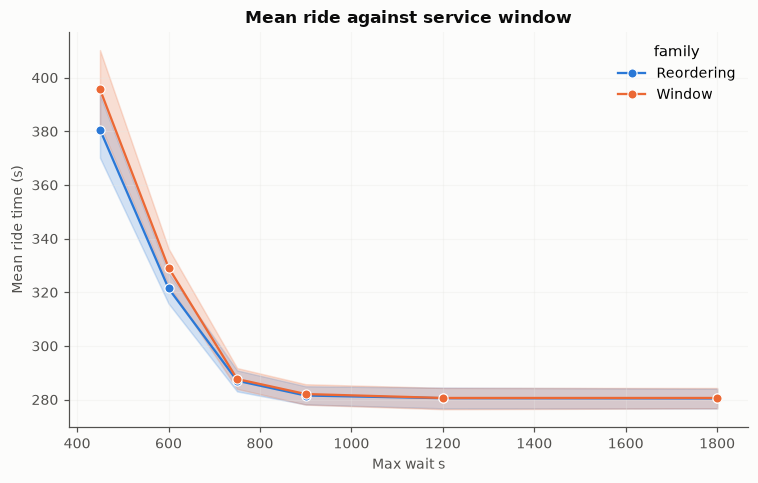

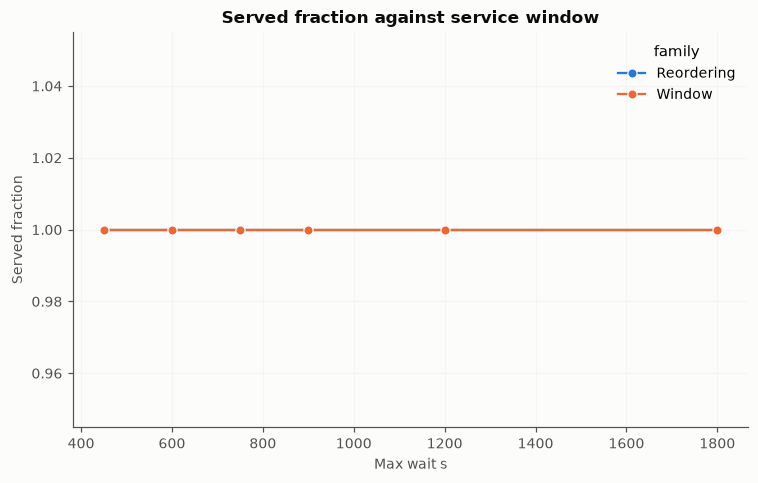

In [10]:
WINDOW_COLUMN = "identity.policy_params.max_wait_s"

if not frame.empty and WINDOW_COLUMN in subset.columns:
    swept = subset[subset[WINDOW_COLUMN].notna()].copy()
    if swept[WINDOW_COLUMN].nunique() > 1:
        swept["family"] = swept["identity.policy_class"].str.replace(
            "InsertionPolicy", "", regex=False)
        from src.experiment import plot_parameter_sweep
        for metric, title in (("kpi.mean_wait_time", "Mean wait"),
                              ("kpi.mean_ride_time", "Mean ride"),
                              ("kpi.served_fraction", "Served fraction")):
            plot_parameter_sweep(swept, x=WINDOW_COLUMN, y=metric,
                                 hue="family",
                                 title=f"{title} against service window")
            plt.show()
    else:
        print("Only one service window recorded in this scenario — "
              "run stage 2 of the campaign notebook for the sweep.")

## CARLA

The transfer demonstration: whether what the synthetic map establishes still
holds when a real vehicle drives a real town. Shown separately because a
CARLA run is a different world, not another row in the same table.

24 runs, 12 requests, 8 seeds, town Town01, 20 NPCs


| Property | Fixed route | Reordering | Window |
| --- | --- | --- | --- |
| Fulfilled requests | 12.0 (±0.0%) | 12.0 (±0.0%) | 12.0 (±0.0%) |
| Cancelled requests | 0.0 (±0.0%) | 0.0 (±0.0%) | 0.0 (±0.0%) |
| Mean wait time | 590.5 s (±16.3%) | 349.8 s (±23.8%) | 333.4 s (±22.7%) |
| P90 wait time | 1031.8 s (±7.0%) | 608.4 s (±26.2%) | 568.0 s (±26.5%) |
| Mean ride time | 580.2 s (±17.3%) | 214.9 s (±16.7%) | 199.6 s (±18.3%) |
| Fulfillment rate | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) |
| Served fraction | 100.0 % (±0.0%) | 100.0 % (±0.0%) | 100.0 % (±0.0%) |
| Throughput | 0.2 req/min (±14.1%) | 0.3 req/min (±9.7%) | 0.3 req/min (±7.7%) |
| Tick snapshots | 3270.5 (±12.9%) | 2405.6 (±9.9%) | 2368.4 (±7.2%) |
| Fulfilled (wait samples) | 12.0 (±0.0%) | 12.0 (±0.0%) | 12.0 (±0.0%) |
| Min wait time | 54.2 s (±73.9%) | 80.7 s (±39.6%) | 66.4 s (±62.0%) |
| Max wait time | 1126.7 s (±5.6%) | 1055.0 s (±42.1%) | 818.9 s (±22.8%) |
| Min ride time | 78.8 s (±47.5%) | 56.6 s (±35.7%) | 56.4 s (±36.0%) |
| Max ride time | 1080.0 s (±9.9%) | 534.0 s (±26.5%) | 415.4 s (±20.1%) |

| policy | fulfilment | wait | ride | throughput | sum | verdict |
| --- | --- | --- | --- | --- | --- | --- |
| Reordering | 100.0% | +40.8% | +63.0% | +34.5% | +138.2% | **PASS** |
| Window | 100.0% | +43.5% | +65.6% | +35.9% | +145.0% | **PASS** |

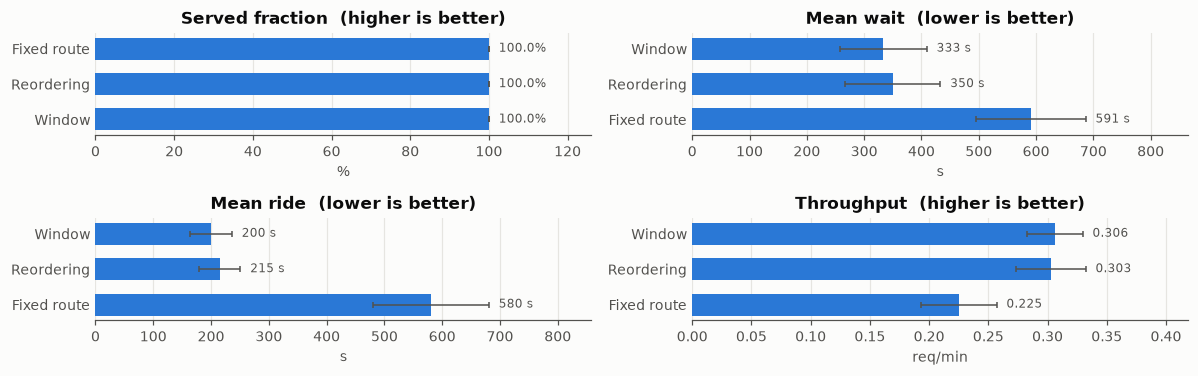

In [11]:
carla = frame[frame["identity.world.backend"] == "CarlaBackend"] \
    if "identity.world.backend" in frame.columns else frame.iloc[0:0]

if carla.empty:
    print("No CARLA runs recorded.")
else:
    biggest = carla.groupby("identity.trial.max_requests").size().idxmax()
    chosen_carla = carla[carla["identity.trial.max_requests"] == biggest]
    wanted_carla = set(chosen_carla["run_id"])
    carla_records = [r for r in records if r.run_id in wanted_carla]
    carla_results = to_results(carla_records, paired=True)
    print(f"{len(carla_records)} runs, {biggest} requests, "
          f"{chosen_carla['identity.seed'].nunique()} seeds, "
          f"town {chosen_carla['identity.world.town'].iloc[0]}, "
          f"{chosen_carla['identity.world.npc_vehicles'].iloc[0]:.0f} NPCs")
    display(Markdown(summarize_results(carla_results).markdown))
    display(Markdown(criteria(carla_results)))
    kpi_panel(carla_results)
    plt.show()

## Was the driving healthy?

Only CARLA reports these. `repaths` is the one to watch: it counts a bus that
stopped making progress for reasons other than a red light or the vehicle in
front, so anything above zero is worth a look rather than a shrug.

In [12]:
DIAGNOSTICS = ["arrivals", "distance_m", "repaths", "queued_ticks",
               "red_light_ticks", "walker_spawn_failures", "unroutable_legs"]

if not carla.empty:
    rows = []
    for record in carla_records:
        row = {"policy": record.identity.policy,
               "seed": record.identity.seed}
        row.update({k: record.backend_stats.get(k) for k in DIAGNOSTICS})
        rows.append(row)
    health = pd.DataFrame(rows)
    display(health.groupby("policy")[DIAGNOSTICS].mean().round(1))
    total_repaths = health["repaths"].sum()
    print(f"total re-routes across all runs: {total_repaths:.0f}"
          + ("  (clean)" if total_repaths == 0 else "  <-- investigate"))

,arrivals,distance_m,repaths,queued_ticks,red_light_ticks,walker_spawn_failures,unroutable_legs
policy,,,,,,,
Fixed route,43.9,12147.9,0.0,2830.8,18999.4,0.0,0.0
Reordering,20.4,8988.1,0.0,1481.0,17302.1,0.0,0.0
Window,20.5,8919.1,0.0,1765.4,16673.1,0.0,0.0


total re-routes across all runs: 0  (clean)


## Provenance

Which commit produced each run, and whether its hash seed was pinned. A run
recorded with `python_hash_seed` unset cannot be reproduced exactly, because
several policies break ties by set-iteration order.

In [13]:
if not frame.empty:
    prov = frame[["provenance.git_commit", "provenance.python_hash_seed"]] \
        .fillna("unset").value_counts().to_frame("runs")
    display(prov)
    unpinned = (frame["provenance.python_hash_seed"].isna()).sum()
    if unpinned:
        print(f"{unpinned} runs were recorded without PYTHONHASHSEED pinned; "
              f"their exact reproduction is not guaranteed.")
    else:
        print("every run was recorded with PYTHONHASHSEED pinned")

,,runs
provenance.git_commit,provenance.python_hash_seed,
3c87be7,0,2280
1a8e962,0,8
2a8d755,0,5
82ae874,0,4
83f368d,0,4
1a80e28,0,4
be47cc2,0,4
0ab5f0f,0,2
dde02f4,0,1


every run was recorded with PYTHONHASHSEED pinned
